<div style="text-align: center;">

  <img src="img/LogoUesc.png" alt="UESC" style="width: 60px; display: block; margin: 0 auto 5px auto;">

  <div style="font-size: 20px;"><strong>UNIVERSIDADE ESTADUAL DE SANTA CRUZ - UESC</strong></div>
  <div style="font-size: 18px;">DEPARTAMENTO DE ENGENHARIAS E COMPUTAÇÃO - DEC</div>
  <div style="font-size: 18px;">Grupo de Pesquisas em Simulações e Controle de Processos</div>

  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

  <div style="font-size: 22px; font-weight: bold; margin-bottom: 10px;">PROGRAMAÇÃO EM PYTHON PARA AS ENGENHARIAS</div>

  <div style="font-size: 18px; margin-top: 10px;"><strong>Tema</strong>: Pandas para Engenharia — Tratamento e Análise de Dados Experimentais.</div>
  <div style="font-size: 18px;"><strong>Prof.  Dr.  E. R. Edwards</strong></div>

  <div style="font-size: 16px; margin-top: 15px;">Ilhéus - BA, Abril de 2027</div>
  
  <hr style="margin: 20px 0; border: 1px solid #0074B7;">

</div>

**Apresentação**

Em laboratórios e plantas industriais, dados de Engenharia chegam em forma de tabelas: leituras de sensores, resultados de ensaios, registros de produção e históricos de controle. O **Pandas** permite ler, organizar, validar, transformar e resumir essas informações. Entretanto, uma tabela bem formatada não garante que seus valores sejam fisicamente plausíveis.

Neste notebook, seguiremos a sequência **problema de Engenharia → modelo e cálculo manual → implementação em Python → interpretação dos resultados**. Os conjuntos de dados são didáticos e não substituem procedimentos laboratoriais, limites operacionais ou especificações oficiais.

**Pré-requisitos:** listas, funções, arquivos, NumPy e noções básicas de gráficos. Para instalar as bibliotecas, se necessário, use `python -m pip install pandas numpy matplotlib` no terminal do ambiente selecionado.

**Sumário**

1. [O problema dos dados experimentais](#secao-1)
2. [Preparando o ambiente e conhecendo o Pandas](#secao-2)
3. [Series: medições com identificação](#secao-3)
4. [DataFrame: a tabela de Engenharia](#secao-4)
5. [Leitura e escrita de arquivos CSV](#secao-5)
6. [Inspeção e tipos de dados](#secao-6)
7. [Seleção de linhas e colunas](#secao-7)
8. [Tratamento de dados ausentes](#secao-8)
9. [Validação de medições e valores suspeitos](#secao-9)
10. [Instrumentação: calibração de transmissor](#secao-10)
11. [Controle de Qualidade: estatística e conformidade](#secao-11)
12. [Controle de Processos: erro e resposta dinâmica](#secao-12)
13. [Processos Químicos: balanço de mistura](#secao-13)
14. [Transferência de Calor: dados de resfriamento](#secao-14)
15. [Ciências dos Materiais: comparação de lotes](#secao-15)
16. [Agrupamento e síntese de experimentos](#secao-16)
17. [Gráficos e comunicação dos resultados](#secao-17)
18. [Organização e exportação de resultados](#secao-18)
19. [Exercícios de consolidação](#secao-19)
20. [Conclusões](#secao-20)

<div id="secao-1" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">1. O problema dos dados experimentais</div>

**Situação de Engenharia.** Um sistema registra temperatura, pressão e vazão ao longo do tempo. Antes de calcular médias ou construir gráficos, precisamos saber quais variáveis foram medidas, suas unidades, quando foram registradas e se existem leituras ausentes ou inconsistentes.

O Pandas organiza dados em **Series** (uma dimensão) e **DataFrames** (tabelas de linhas e colunas). A interpretação física, entretanto, continua sendo responsabilidade do engenheiro.

<div id="secao-2" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">2. Preparando o ambiente e conhecendo o Pandas</div>

Importaremos o Pandas com o nome convencional `pd`, o NumPy para cálculos numéricos e o Matplotlib para gráficos. O método `pd.__version__` permite verificar a versão instalada.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 2.3.3
NumPy: 2.3.5


<div id="secao-3" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">3. Series: medições com identificação</div>

Uma **Series** associa valores a índices. Considere quatro temperaturas de um processo: 68, 71, 74 e 76 °C. A média calculada manualmente é

$$\overline{T}=\frac{68+71+74+76}{4}=72{,}25\ ^\circ\mathrm{C}.$$

O índice pode representar o instante de cada medição.

In [2]:
temperaturas = pd.Series([68.0, 71.0, 74.0, 76.0], index=[0, 1, 2, 3], name="Temperatura (°C)")
print(temperaturas)
print(f"Média: {temperaturas.mean():.2f} °C")
print("Temperatura no minuto 2:", temperaturas.loc[2], "°C")

0    68.0
1    71.0
2    74.0
3    76.0
Name: Temperatura (°C), dtype: float64
Média: 72.25 °C
Temperatura no minuto 2: 74.0 °C


**Interpretação:** a média é 72,25 °C. O índice indica a posição temporal adotada; se as amostragens não forem regulares, os instantes reais devem ser armazenados explicitamente.

<div id="secao-4" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">4. DataFrame: a tabela de Engenharia</div>

Um **DataFrame** reúne colunas com diferentes significados físicos. Vamos organizar cinco registros de um processo térmico. Cada linha representa um instante; cada coluna, uma grandeza acompanhada de sua unidade no nome.

In [3]:
dados_processo = pd.DataFrame({
    "tempo_min": [0, 1, 2, 3, 4],
    "temperatura_C": [70.0, 72.0, 75.0, 77.0, 79.0],
    "pressao_bar": [2.0, 2.1, 2.1, 2.2, 2.2],
    "vazao_L_min": [5.0, 5.0, 4.8, 5.1, 5.0],
})
print(dados_processo.to_string(index=False))
print("Formato (linhas, colunas):", dados_processo.shape)

 tempo_min  temperatura_C  pressao_bar  vazao_L_min
         0           70.0          2.0          5.0
         1           72.0          2.1          5.0
         2           75.0          2.1          4.8
         3           77.0          2.2          5.1
         4           79.0          2.2          5.0
Formato (linhas, colunas): (5, 4)


**Interpretação:** a tabela possui cinco registros e quatro variáveis. O nome de cada coluna informa a grandeza e a unidade, reduzindo ambiguidades nas análises.

<div id="secao-5" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">5. Leitura e escrita de arquivos CSV</div>

**Problema de Engenharia — armazenamento.** Um registro experimental deve poder ser recuperado sem redigitação. O formato CSV armazena tabelas em texto, com separadores entre campos.

No exemplo, o arquivo será criado automaticamente na pasta `dados_notebook14`, dentro do diretório de execução do Jupyter. O uso de `index=False` impede a criação de uma coluna adicional com o índice interno do DataFrame.

In [4]:
pasta = Path("dados_notebook14")
pasta.mkdir(exist_ok=True)
caminho_csv = pasta / "historico_processo.csv"
dados_processo.to_csv(caminho_csv, index=False, encoding="utf-8")
dados_lidos = pd.read_csv(caminho_csv)
print("Arquivo:", caminho_csv)
print(dados_lidos.head().to_string(index=False))

Arquivo: dados_notebook14\historico_processo.csv
 tempo_min  temperatura_C  pressao_bar  vazao_L_min
         0           70.0          2.0          5.0
         1           72.0          2.1          5.0
         2           75.0          2.1          4.8
         3           77.0          2.2          5.1
         4           79.0          2.2          5.0


**Interpretação:** os dados foram gravados e lidos novamente. Arquivos reais podem utilizar `;` como separador e vírgula decimal; nesses casos, `pd.read_csv` permite configurar `sep=";"` e `decimal=","`.

<div id="secao-6" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">6. Inspeção e tipos de dados</div>

Antes de analisar uma planilha, verifique a quantidade de registros, os nomes das colunas, os tipos de dados e a existência de valores ausentes. Uma coluna numérica importada como texto não deve ser utilizada diretamente em operações aritméticas.

In [5]:
print("Colunas:", dados_lidos.columns.tolist())
print("Tipos de dados:\n", dados_lidos.dtypes)
print("Primeiras linhas:\n", dados_lidos.head(3))
print("Valores ausentes por coluna:\n", dados_lidos.isna().sum())

Colunas: ['tempo_min', 'temperatura_C', 'pressao_bar', 'vazao_L_min']
Tipos de dados:
 tempo_min          int64
temperatura_C    float64
pressao_bar      float64
vazao_L_min      float64
dtype: object
Primeiras linhas:
    tempo_min  temperatura_C  pressao_bar  vazao_L_min
0          0           70.0          2.0          5.0
1          1           72.0          2.1          5.0
2          2           75.0          2.1          4.8
Valores ausentes por coluna:
 tempo_min        0
temperatura_C    0
pressao_bar      0
vazao_L_min      0
dtype: int64


<div id="secao-7" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">7. Seleção de linhas e colunas</div>

**Seleção de dados.** Para escolher colunas pelo nome, use `df["coluna"]` ou `df[["coluna1", "coluna2"]]`. O método `.loc` seleciona por rótulos e condições; `.iloc` seleciona por posições numéricas.

Vamos selecionar as leituras de temperatura acima de 74 °C, sem interpretar esse valor como um limite de segurança.

In [6]:
print("Somente temperaturas:\n", dados_lidos["temperatura_C"])
print("Tempo e temperatura:\n", dados_lidos[["tempo_min", "temperatura_C"]])
print("Temperaturas acima de 74 °C:\n", dados_lidos.loc[dados_lidos["temperatura_C"] > 74, ["tempo_min", "temperatura_C"]])
print("Primeiro registro:\n", dados_lidos.iloc[0])

Somente temperaturas:
 0    70.0
1    72.0
2    75.0
3    77.0
4    79.0
Name: temperatura_C, dtype: float64
Tempo e temperatura:
    tempo_min  temperatura_C
0          0           70.0
1          1           72.0
2          2           75.0
3          3           77.0
4          4           79.0
Temperaturas acima de 74 °C:
    tempo_min  temperatura_C
2          2           75.0
3          3           77.0
4          4           79.0
Primeiro registro:
 tempo_min         0.0
temperatura_C    70.0
pressao_bar       2.0
vazao_L_min       5.0
Name: 0, dtype: float64


<div id="secao-8" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">8. Tratamento de dados ausentes</div>

**Problema de Engenharia — falha de aquisição.** Um sensor pode deixar de registrar uma leitura. Dados ausentes não equivalem a zero. O Pandas utiliza `NaN` para representar valores numéricos faltantes.

Considere temperaturas de 70, 72, ausência de leitura, 76 e 78 °C. A média das quatro medições disponíveis é

$$\overline{T}=\frac{70+72+76+78}{4}=74\ ^\circ\mathrm{C}.$$

A média ignora o valor ausente, mas isso não significa que a ausência possa ser ignorada na avaliação da qualidade do experimento.

In [7]:
falhas = pd.DataFrame({"tempo_min": [0, 1, 2, 3, 4], "temperatura_C": [70.0, 72.0, np.nan, 76.0, 78.0]})
print("Tabela original:\n", falhas)
print("Ausências:", falhas["temperatura_C"].isna().sum())
print(f"Média das leituras disponíveis: {falhas['temperatura_C'].mean():.2f} °C")
falhas["temperatura_interpolada_C"] = falhas["temperatura_C"].interpolate(method="linear")
print("Tabela com interpolação demonstrativa:\n", falhas)

Tabela original:
    tempo_min  temperatura_C
0          0           70.0
1          1           72.0
2          2            NaN
3          3           76.0
4          4           78.0
Ausências: 1
Média das leituras disponíveis: 74.00 °C
Tabela com interpolação demonstrativa:
    tempo_min  temperatura_C  temperatura_interpolada_C
0          0           70.0                       70.0
1          1           72.0                       72.0
2          2            NaN                       74.0
3          3           76.0                       76.0
4          4           78.0                       78.0


**Interpretação:** a interpolação produz 74 °C para o instante sem leitura, supondo variação linear entre os pontos vizinhos. **Esse valor é uma estimativa, não uma medição**; em processos com transientes rápidos, a hipótese pode ser inadequada.

<div id="secao-9" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">9. Validação de medições e valores suspeitos</div>

**Problema de Engenharia — plausibilidade física.** Considere leituras de pressão em um sistema didático: 2,0; 2,1; 25,0; 2,2 bar. A terceira leitura destoa das demais, mas não podemos eliminá-la automaticamente: ela pode indicar erro de instrumentação ou um evento real.

Para demonstrar a validação, adotaremos a faixa **hipotética de análise** de 0 a 5 bar. Ela não representa um limite industrial de operação.

In [8]:
pressoes = pd.DataFrame({"tempo_min": [0, 1, 2, 3], "pressao_bar": [2.0, 2.1, 25.0, 2.2]})
pressoes["dentro_faixa_didatica"] = pressoes["pressao_bar"].between(0.0, 5.0)
print(pressoes.to_string(index=False))
print("Registros para investigação:\n", pressoes.loc[~pressoes["dentro_faixa_didatica"]])

 tempo_min  pressao_bar  dentro_faixa_didatica
         0          2.0                   True
         1          2.1                   True
         2         25.0                  False
         3          2.2                   True
Registros para investigação:
    tempo_min  pressao_bar  dentro_faixa_didatica
2          2         25.0                  False


**Interpretação:** o registro de 25 bar foi sinalizado para investigação. O procedimento correto depende de evidências: histórico de alarmes, calibração, estado do processo e registros operacionais.

<div id="secao-10" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">10. Instrumentação: calibração de transmissor</div>

**Problema de Engenharia — Instrumentação.** Um transmissor ideal de pressão representa 0 a 10 bar por um sinal de 4 a 20 mA. A equação de conversão linear é

$$P=\frac{I-4}{16}\times10.$$

Para 12 mA, o cálculo manual fornece $P=5$ bar. Vamos organizar correntes e pressões convertidas em uma tabela.

In [9]:
calibracao = pd.DataFrame({"corrente_mA": [4.0, 8.0, 12.0, 16.0, 20.0]})
calibracao["pressao_bar"] = (calibracao["corrente_mA"] - 4.0) * 10.0 / 16.0
print(calibracao.to_string(index=False))

 corrente_mA  pressao_bar
         4.0          0.0
         8.0          2.5
        12.0          5.0
        16.0          7.5
        20.0         10.0


**Interpretação:** o valor de 12 mA corresponde a 5 bar. A relação apresentada é a escala nominal ideal; uma calibração real requer padrões rastreáveis, avaliação de erros e incerteza de medição.

<div id="secao-11" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">11. Controle de Qualidade: estatística e conformidade</div>

**Problema de Engenharia — Controle de Qualidade.** Um laboratório analisou concentrações de 9,8; 10,1; 10,4; 9,7 e 10,0 g/L. A média manual é

$$\overline{C}=\frac{9{,}8+10{,}1+10{,}4+9{,}7+10{,}0}{5}=10{,}0\ \mathrm{g/L}.$$

Adotaremos, **apenas para este exercício**, a faixa de aceitação de 9,5 a 10,5 g/L. A variabilidade será descrita pelo desvio-padrão **amostral**, calculado com divisor $n-1$.

In [10]:
qualidade = pd.DataFrame({"amostra": [1, 2, 3, 4, 5], "concentracao_g_L": [9.8, 10.1, 10.4, 9.7, 10.0]})
qualidade["conforme_exercicio"] = qualidade["concentracao_g_L"].between(9.5, 10.5)
print(qualidade.to_string(index=False))
print(f"Média: {qualidade['concentracao_g_L'].mean():.2f} g/L")
print(f"Desvio-padrão amostral: {qualidade['concentracao_g_L'].std(ddof=1):.3f} g/L")
print("Amostras dentro da faixa:", int(qualidade["conforme_exercicio"].sum()), "de", len(qualidade))

 amostra  concentracao_g_L  conforme_exercicio
       1               9.8                True
       2              10.1                True
       3              10.4                True
       4               9.7                True
       5              10.0                True
Média: 10.00 g/L
Desvio-padrão amostral: 0.274 g/L
Amostras dentro da faixa: 5 de 5


**Interpretação:** todas as amostras estão dentro da faixa didática. Essa observação não substitui um plano de amostragem nem autoriza conclusões sobre a conformidade de um lote industrial.

<div id="secao-12" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">12. Controle de Processos: erro e resposta dinâmica</div>

**Problema de Engenharia — Controle de Processos Aplicado.** Para uma referência de temperatura $T_{SP}=80$ °C, o erro de controle é

$$e_k=T_{SP}-T_k.$$

Se $T_k=72$ °C, então $e_k=8$ °C. Calcularemos os erros ao longo de cinco instantes e o erro absoluto médio:

$$\mathrm{EAM}=\frac{1}{n}\sum_{k=1}^{n}|e_k|.$$

Para os erros 8, 5, 2, 1 e 0 °C, $\mathrm{EAM}=3{,}2$ °C.

In [11]:
controle = pd.DataFrame({"tempo_min": [0, 1, 2, 3, 4], "temperatura_C": [72.0, 75.0, 78.0, 79.0, 80.0]})
T_SP = 80.0
controle["erro_C"] = T_SP - controle["temperatura_C"]
controle["erro_absoluto_C"] = controle["erro_C"].abs()
print(controle.to_string(index=False))
print(f"Erro absoluto médio: {controle['erro_absoluto_C'].mean():.2f} °C")

 tempo_min  temperatura_C  erro_C  erro_absoluto_C
         0           72.0     8.0              8.0
         1           75.0     5.0              5.0
         2           78.0     2.0              2.0
         3           79.0     1.0              1.0
         4           80.0     0.0              0.0
Erro absoluto médio: 3.20 °C


**Interpretação:** o erro diminui até zero na sequência apresentada. Isso não demonstra, isoladamente, estabilidade, robustez ou desempenho de um controlador em outras condições.

<div id="secao-13" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">13. Processos Químicos: balanço de mistura</div>

**Problema de Engenharia — Processos Químicos de Fabricação.** Duas correntes são misturadas sem reação química. Sob as hipóteses didáticas de volumes aditivos e concentrações expressas na mesma base, o balanço de soluto fornece

$$C_m=\frac{Q_1C_1+Q_2C_2}{Q_1+Q_2}.$$

Para $Q_1=2$ L/min, $C_1=10$ g/L, $Q_2=3$ L/min e $C_2=4$ g/L, calculamos manualmente

$$C_m=\frac{2\times10+3\times4}{2+3}=6{,}4\ \mathrm{g/L}.$$

Vamos analisar três configurações de vazão.

In [12]:
misturas = pd.DataFrame({"ensaio": [1, 2, 3], "Q1_L_min": [2.0, 3.0, 4.0], "Q2_L_min": [3.0, 2.0, 1.0]})
C1, C2 = 10.0, 4.0
misturas["vazao_total_L_min"] = misturas["Q1_L_min"] + misturas["Q2_L_min"]
if (misturas["vazao_total_L_min"] <= 0).any():
    raise ValueError("A vazão total deve ser positiva.")
misturas["concentracao_mistura_g_L"] = (misturas["Q1_L_min"] * C1 + misturas["Q2_L_min"] * C2) / misturas["vazao_total_L_min"]
print(misturas.to_string(index=False))

 ensaio  Q1_L_min  Q2_L_min  vazao_total_L_min  concentracao_mistura_g_L
      1       2.0       3.0                5.0                       6.4
      2       3.0       2.0                5.0                       7.6
      3       4.0       1.0                5.0                       8.8


**Interpretação:** o aumento da participação da corrente de maior concentração eleva a concentração final. Em um processo real, a validade do modelo depende das propriedades da mistura e das hipóteses adotadas.

<div id="secao-14" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">14. Transferência de Calor: dados de resfriamento</div>

**Problema de Engenharia — Transferência de Calor.** Considere a evolução da temperatura de um corpo durante resfriamento. Para uma demonstração, usaremos a lei de resfriamento de Newton com temperatura ambiente constante:

$$T(t)=T_\infty+(T_0-T_\infty)e^{-kt}.$$

Adotando $T_0=90$ °C, $T_\infty=25$ °C e $k=0{,}1$ min$^{-1}$, a temperatura inicial calculada é $T(0)=25+(90-25)=90$ °C. Geraremos uma tabela de tempos e temperaturas do modelo.

In [13]:
tempos_min = np.arange(0, 31, 5)
T_amb, T_inicial, k_min = 25.0, 90.0, 0.1
resfriamento = pd.DataFrame({"tempo_min": tempos_min})
resfriamento["temperatura_C"] = T_amb + (T_inicial - T_amb) * np.exp(-k_min * resfriamento["tempo_min"])
print(resfriamento.round(2).to_string(index=False))

 tempo_min  temperatura_C
         0          90.00
         5          64.42
        10          48.91
        15          39.50
        20          33.80
        25          30.34
        30          28.24


**Interpretação:** a temperatura se aproxima da ambiente ao longo do tempo. O modelo pressupõe parâmetros constantes e não descreve necessariamente todos os mecanismos de transferência de calor de um sistema real.

<div id="secao-15" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">15. Ciências dos Materiais: comparação de lotes</div>

**Problema de Engenharia — Ciências dos Materiais.** Um laboratório realiza quatro medições de dureza Vickers em cada um de três lotes. Queremos comparar a média e a dispersão das medições de cada lote.

Para o lote A, com 205, 210, 208 e 217 HV, a média manual é

$$\overline{H}_A=\frac{205+210+208+217}{4}=210\ \mathrm{HV}.$$

O Pandas permite organizar as medições por lote sem perder a identificação de cada amostra.

In [14]:
dureza = pd.DataFrame({
    "lote": ["A"]*4 + ["B"]*4 + ["C"]*4,
    "amostra": [1, 2, 3, 4]*3,
    "dureza_HV": [205, 210, 208, 217, 198, 201, 204, 199, 214, 216, 212, 218],
})
print(dureza.to_string(index=False))
print("Médias por lote (HV):\n", dureza.groupby("lote")["dureza_HV"].mean())

lote  amostra  dureza_HV
   A        1        205
   A        2        210
   A        3        208
   A        4        217
   B        1        198
   B        2        201
   B        3        204
   B        4        199
   C        1        214
   C        2        216
   C        3        212
   C        4        218
Médias por lote (HV):
 lote
A    210.0
B    200.5
C    215.0
Name: dureza_HV, dtype: float64


**Interpretação:** diferenças entre médias podem orientar novas investigações. Sem informações sobre incerteza, repetibilidade, processo de fabricação e amostragem, não devemos atribuir causas às diferenças observadas.

<div id="secao-16" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">16. Agrupamento e síntese de experimentos</div>

O método `groupby` reúne registros por uma categoria, como lote, turno ou condição experimental. O método `agg` calcula várias estatísticas de uma vez. Isso permite construir tabelas de síntese mantendo rastreabilidade entre dados originais e resultados.

In [15]:
resumo_lotes = dureza.groupby("lote")["dureza_HV"].agg(
    quantidade="count", media="mean", minimo="min", maximo="max", desvio_amostral="std"
).round(2)
print(resumo_lotes)
print("Média global (HV):", round(dureza["dureza_HV"].mean(), 2))

      quantidade  media  minimo  maximo  desvio_amostral
lote                                                    
A              4  210.0     205     217             5.10
B              4  200.5     198     204             2.65
C              4  215.0     212     218             2.58
Média global (HV): 208.5


<div id="secao-17" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">17. Gráficos e comunicação dos resultados</div>

**Visualização e interpretação.** Um gráfico ajuda a observar tendências e comparar resultados, mas deve apresentar unidades e identificar claramente os dados. Usaremos o Matplotlib, estudado no Notebook 13, para representar o resfriamento e as temperaturas do sistema de controle.

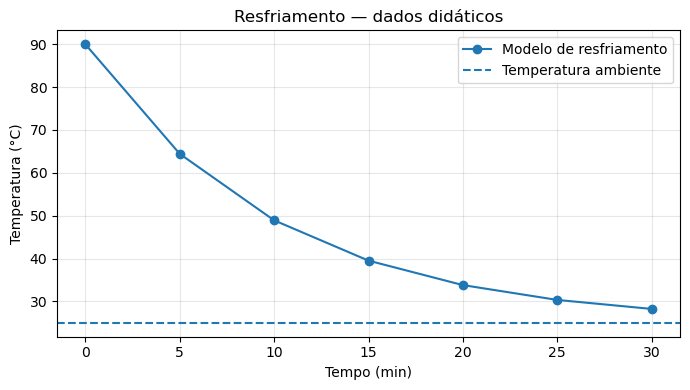

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(resfriamento["tempo_min"], resfriamento["temperatura_C"], marker="o", label="Modelo de resfriamento")
ax.axhline(T_amb, linestyle="--", label="Temperatura ambiente")
ax.set_xlabel("Tempo (min)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Resfriamento — dados didáticos")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

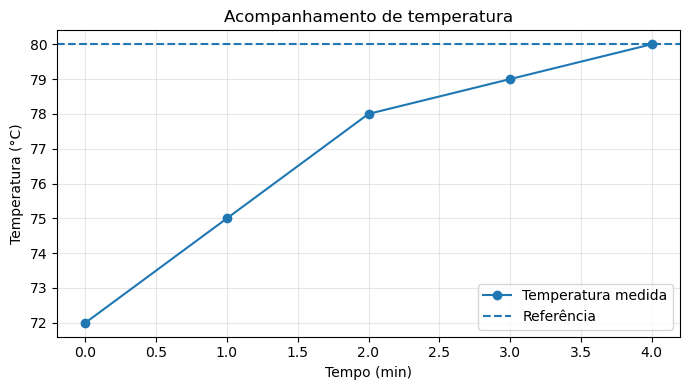

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(controle["tempo_min"], controle["temperatura_C"], marker="o", label="Temperatura medida")
ax.axhline(T_SP, linestyle="--", label="Referência")
ax.set_xlabel("Tempo (min)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Acompanhamento de temperatura")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação:** o primeiro gráfico ilustra a aproximação da temperatura à condição ambiente; o segundo mostra as medições aproximando-se da referência. Os gráficos descrevem apenas os dados e as hipóteses adotadas.

<div id="secao-18" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">18. Organização e exportação de resultados</div>

Ao concluir uma análise, é recomendável exportar tabelas com nomes de colunas, unidades e identificação dos ensaios. Salvaremos os resultados em arquivos CSV. Também é importante registrar a origem dos dados, o método de tratamento e as decisões tomadas sobre valores ausentes ou suspeitos.

In [18]:
arquivo_qualidade = pasta / "controle_qualidade.csv"
arquivo_resumo = pasta / "resumo_dureza_lotes.csv"
qualidade.to_csv(arquivo_qualidade, index=False, encoding="utf-8")
resumo_lotes.to_csv(arquivo_resumo, index=True, encoding="utf-8")
print("Arquivos gerados:")
print("-", arquivo_qualidade)
print("-", arquivo_resumo)

Arquivos gerados:
- dados_notebook14\controle_qualidade.csv
- dados_notebook14\resumo_dureza_lotes.csv


<div id="secao-19" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">19. Exercícios de consolidação</div>

**Exercício 1 — Instrumentação.** Construa um DataFrame com correntes de 4, 6, 10, 14, 18 e 20 mA. Converta para temperatura de um transmissor ideal configurado de 0 a 200 °C. Calcule manualmente a temperatura correspondente a 12 mA e compare com a equação.

**Exercício 2 — Controle de Qualidade.** Organize as concentrações 7,8; 8,0; 8,2; 8,1 e 7,9 g/L. Calcule média, mediana, amplitude e desvio-padrão amostral. Discuta por que um resultado médio aceitável não garante conformidade de todas as amostras.

**Exercício 3 — Falhas de aquisição.** Crie uma tabela de temperaturas com uma leitura ausente. Compare a média dos valores observados com a média após interpolação linear. Explique as hipóteses envolvidas.

**Exercício 4 — Controle de Processos.** Para referência de 90 °C e medições de 82, 85, 87, 89 e 91 °C, calcule os erros, os valores absolutos e o erro absoluto médio. Identifique quando o erro muda de sinal.

**Exercício 5 — Processos Químicos.** Organize três misturas com diferentes vazões. Aplique o balanço de soluto para concentrações de entrada de 12 e 3 g/L. Verifique que nenhuma vazão total seja nula.

**Exercício 6 — Ciências dos Materiais.** Organize quatro medições de dureza para cada um de três lotes. Calcule estatísticas por lote e discuta quais informações adicionais seriam necessárias antes de comparar formalmente os materiais.

**Desafio integrador — dados de processo.** Crie um CSV contendo tempo, temperatura e pressão de um processo didático. Leia o arquivo com Pandas, identifique eventuais valores ausentes, calcule estatísticas, represente as temperaturas em gráfico e exporte uma tabela final. Registre explicitamente todos os critérios de tratamento adotados.

<div id="secao-20" style="background-color:#f1faff; border-left:6px solid #0074B7; color:#003366; border-radius:8px; padding:15px 20px; font-size:20px; font-weight:bold;">20. Conclusões</div>

O Pandas permite transformar medições dispersas em informações organizadas e verificáveis. Aprendemos a criar Series e DataFrames, importar e exportar CSV, inspecionar tipos, selecionar registros, identificar valores ausentes, sinalizar medições suspeitas, calcular estatísticas e agrupar ensaios.

**A principal lição de Engenharia é que tratar dados não significa apenas executar comandos:** é necessário preservar unidades, compreender o processo, justificar hipóteses e interpretar os resultados à luz dos fenômenos físicos. O próximo notebook aprofundará a solução computacional de problemas por métodos numéricos.

<div style="text-align: center; font-size: 12px; color: gray; margin-top: 40px; padding-top: 15px; border-top: 1px solid #dddddd;">
  Material desenvolvido pelo Grupo de Pesquisas em Modelagem Computacional da UESC.<br>
  © 2026 — Todos os direitos reservados. Uso comercial somente mediante autorização.
</div>